# Studiul de caz 1 - Detectarea explicabilă a fraudei: alegerea modelului, explicațiile și pragurile de alertă

Master - Rețele neuronale și deep learning (NN) - Prof. Daniel Traian Pele

Academia de Studii Economice din București - Academia Română, Institutul de Prognoză Economică

In [1]:
# Google Colab: copiem repo-ul cursului, ca datele și rezultatele salvate să fie găsite
import os, subprocess, sys
if 'google.colab' in sys.modules and not os.getcwd().startswith('/content/NEURAL_BIZ'):
    if not os.path.isdir('/content/NEURAL_BIZ'):
        subprocess.run(['git', 'clone', '-q', '--depth', '1', 'https://github.com/danpele/NEURAL_BIZ.git', '/content/NEURAL_BIZ'], check=True)
    os.chdir('/content/NEURAL_BIZ/cases/C1_fraud_xai')

In [2]:
import os, sys, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, os.path.join("..", "common"))   # shared helpers: cases/common/case_utils.py
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import case_utils as cu
LANG = "ro"            # "en" or "ro": language of the charts shown below (both are saved)
cu.set_lang(LANG)
T = lambda en, ro: cu.T(LANG, en, ro)
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 30)
%matplotlib inline

**Lucrarea de referință.** Diaconu, D. și Pele, D. T. (2026). Explainable AI in financial fraud detection: Evidence from the IEEE-CIS fraud dataset.
*Proceedings of the International Conference on Business Excellence (PICBE)*, 20(1), 118-132. doi:10.2478/picbe-2026-0015

**Conținutul notebook-ului.** Replicăm, într-o formă simplificată, procedura de inteligență artificială explicabilă (XAI, *explainable artificial intelligence*) din lucrare pe datele de fraudă cu carduri ale cursului
(Worldline și ULB, Université Libre de Bruxelles, Machine Learning Group; deținători europeni de carduri, septembrie 2013):
(1) o regresie logistică drept reper, arbori de decizie construiți secvențial (XGBoost, *eXtreme Gradient Boosting*), ca în lucrare, și un perceptron multistrat (MLP, *multilayer perceptron*) cu *dropout*,
penalizarea ponderilor și oprire timpurie (cursurile 1 și 3), fiecare antrenat cu cinci valori inițiale ale generatorului aleator; (2) explicații SHAP (*SHapley Additive exPlanations*) globale pentru arbori și pentru rețea și verificarea faptului
că cele două modele se sprijină pe aceleași variabile; (3) explicația locală a unei alerte; (4) o analiză prin *eliminare* (ablation), analogul, în spațiul variabilelor, al eliminării de muchii și noduri din lucrare;
(5) o regulă de alertă derivată din costul unei verificări și din suma expusă riscului.

**Adaptarea pentru curs.** Lucrarea folosește datele IEEE-CIS (Institute of Electrical and Electronics Engineers, Computational Intelligence Society; 590.540 de tranzacții, 432 de variabile)
și o împărțire aleatoare 70/30 și adaugă un model pe un graf eterogen (GraphSAGE), care leagă tranzacțiile prin identități, dispozitive și adrese comune.
Datele noastre au 30 de variabile anonimizate și nu conțin chei ale entităților, de aceea nivelul de graf nu face parte din acest notebook (studiul de caz 3 lucrează pe un graf de tranzacții); cele două zile sînt împărțite
*în ordine cronologică* (60 % antrenare, 20 % validare, 20 % test).

## 1. Datele și împărțirea cronologică

sampling rate of legitimate transactions beta = 0.1000
train     :  17354 rows, 360 frauds, hours   0.0- 33.4, population    170297 transactions, fraud rate 0.211 %
validation:   5785 rows,  57 frauds, hours  33.4- 40.3, population     57336 transactions, fraud rate 0.099 %
test      :   5785 rows,  75 frauds, hours  40.3- 48.0, population     57174 transactions, fraud rate 0.131 %


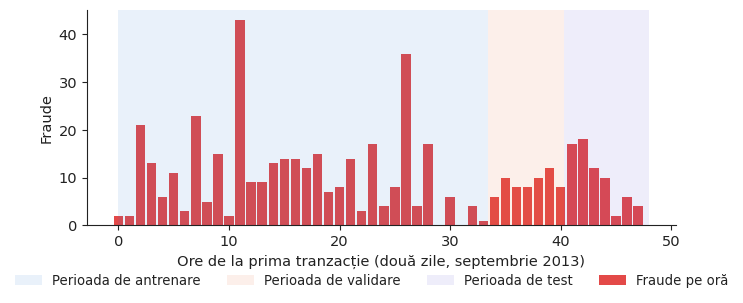

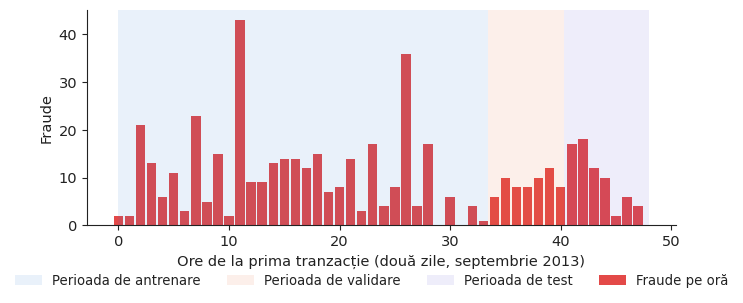

In [3]:
os.environ["OMP_NUM_THREADS"] = "1"          # PyTorch and XGBoost in the same process
import torch                                  # import torch before sklearn / shap
torch.set_num_threads(4)
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve
import xgboost as xgb, shap
SEEDS = [0, 1, 2, 3, 4]                      # five seeds for every trained model

d = cu.fraud().sort_values(["Time", "row_id"]).reset_index(drop=True)
d["log_amount"] = np.log1p(d.Amount)
FEAT = [f"V{i}" for i in range(1, 29)] + ["log_amount"]
n = len(d); a, b = int(0.6 * n), int(0.8 * n)          # time order: 60 % train, 20 % validation, 20 % test
split = np.array(["train"] * a + ["validation"] * (b - a) + ["test"] * (n - b))
d["split"] = split
X = d[FEAT].values; y = d.Class.values; w = d.weight.values   # weight = inverse sampling rate (legitimate rows: 10 % sample)
itr, iva, ite = split == "train", split == "validation", split == "test"
BETA = 1 / d.loc[d.Class == 0, "weight"].iloc[0]           # sampling rate of the legitimate class
print("sampling rate of legitimate transactions beta = %.4f" % BETA)
for nm, m in [("train", itr), ("validation", iva), ("test", ite)]:
    print(f"{nm:10s}: {m.sum():6d} rows, {int(y[m].sum()):3d} frauds, hours {d.Time[m].min() / 3600:5.1f}-{d.Time[m].max() / 3600:5.1f}, "
          f"population {w[m].sum():9.0f} transactions, fraud rate {100 * y[m].sum() / w[m].sum():.3f} %")
sc = StandardScaler().fit(X[itr])            # scaler fitted on training rows only
Xs = sc.transform(X)
HOURS = (d.Time.max() - d.Time[ite].min()) / 3600
def fig_time(lang):
    fig, ax = plt.subplots(figsize=(7.6, 2.8))
    h = (d.Time // 3600).astype(int)
    tot = pd.Series(w).groupby(h).sum(); fr = pd.Series(y).groupby(h).sum()
    ax.bar(fr.index, fr.values, width=0.85, color=cu.PAL["c8"], label=cu.T(lang, "Frauds per hour", "Fraude pe oră"))
    ax.set_xlabel(cu.T(lang, "Hours since the first transaction (two days, September 2013)", "Ore de la prima tranzacție (două zile, septembrie 2013)"))
    ax.set_ylabel(cu.T(lang, "Frauds", "Fraude"))
    for (s_, c_, en, ro) in [(itr, cu.PAL["RO"], "training", "antrenare"), (iva, cu.PAL["DE_LU"], "validation", "validare"), (ite, cu.PAL["c7"], "test", "test")]:
        t0, t1 = d.Time[s_].min() / 3600, d.Time[s_].max() / 3600
        ax.axvspan(t0, t1, color=c_, alpha=0.10, lw=0, label=cu.T(lang, "Period: " + en, "Perioada de " + ro))
    cu.legend_bottom(fig, ncol=4)
    return fig
cu.save_both(fig_time, "f1_time_split")

## 2. Trei modele, fiecare cu cinci rulări

In [4]:
def correct(ps):
    """Undo the under-sampling of the legitimate class: p = beta*ps / (beta*ps - ps + 1) (Dal Pozzolo et al., 2015)."""
    return BETA * ps / (BETA * ps - ps + 1)

def metrics(p, m=ite, budget=0.005):
    """Population-level metrics with the sampling weights; budget = share of transactions that can be reviewed."""
    yy, pp, ww = y[m], p[m], w[m]
    o = np.argsort(-pp); cw = np.cumsum(ww[o]) / ww.sum()
    k = np.searchsorted(cw, budget) + 1
    sel = o[:k]
    return dict(AUC=roc_auc_score(yy, pp, sample_weight=ww), PRAUC=average_precision_score(yy, pp, sample_weight=ww),
                Recall=yy[sel].sum() / yy.sum(), Precision=(yy[sel] * ww[sel]).sum() / ww[sel].sum())

P = {"Logistic regression": [], "XGBoost": [], "MLP": []}
for s in SEEDS:
    lr = LogisticRegression(C=1.0, max_iter=2000, random_state=s).fit(Xs[itr], y[itr])
    P["Logistic regression"].append(lr.predict_proba(Xs)[:, 1])
    xm = xgb.XGBClassifier(n_estimators=1000, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8,
                           eval_metric="logloss", early_stopping_rounds=100, random_state=s, n_jobs=4, tree_method="hist")
    xm.fit(X[itr], y[itr], eval_set=[(X[iva], y[iva])], verbose=False)
    P["XGBoost"].append(xm.predict_proba(X)[:, 1])
    if s == 0:
        XGB0, LR0 = xm, lr
print("XGBoost (seed 0): best iteration", XGB0.best_iteration)

class MLP(torch.nn.Module):
    def __init__(self, p_in, h1=64, h2=32, drop=0.2):
        super().__init__()
        self.net = torch.nn.Sequential(torch.nn.Linear(p_in, h1), torch.nn.ReLU(), torch.nn.Dropout(drop),
                                       torch.nn.Linear(h1, h2), torch.nn.ReLU(), torch.nn.Dropout(drop), torch.nn.Linear(h2, 1))
    def forward(self, x):
        return self.net(x)

def train_mlp(seed, cols=None, epochs=80, patience=10):
    torch.manual_seed(seed); np.random.seed(seed)
    cols = list(range(Xs.shape[1])) if cols is None else cols
    Xt = torch.tensor(Xs[:, cols], dtype=torch.float32)
    m = MLP(len(cols)); opt = torch.optim.Adam(m.parameters(), lr=1e-3, weight_decay=1e-4)
    lossf = torch.nn.BCEWithLogitsLoss()
    tr = np.where(itr)[0]; yt = torch.tensor(y, dtype=torch.float32)
    best, best_state, bad = -1, None, 0
    g = np.random.default_rng(seed)
    for ep in range(epochs):
        m.train(); g.shuffle(tr)
        for j in range(0, len(tr), 256):
            bi = tr[j:j + 256]
            opt.zero_grad(); l = lossf(m(Xt[bi]).squeeze(1), yt[bi]); l.backward(); opt.step()
        m.eval()
        with torch.no_grad():
            pv = torch.sigmoid(m(Xt[iva])).squeeze(1).numpy()
        ap = average_precision_score(y[iva], pv)                 # early stopping on validation PR-AUC
        if ap > best:
            best, bad, best_state = ap, 0, {k: v.clone() for k, v in m.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                break
    m.load_state_dict(best_state); m.eval()
    with torch.no_grad():
        p = torch.sigmoid(m(Xt)).squeeze(1).numpy()
    return m, p

for s in SEEDS:
    m_, p_ = train_mlp(s)
    P["MLP"].append(p_)
    if s == 0:
        MLP0 = m_
P = {k: [correct(p) for p in v] for k, v in P.items()}        # probabilities on the population scale
rows = {}
for k, v in P.items():
    ms = pd.DataFrame([metrics(p) for p in v])
    rows[k] = ms.mean().to_dict() | {"PRAUC_sd": ms.PRAUC.std()}
res = pd.DataFrame(rows).T
print(res.round(4))

XGBoost (seed 0): best iteration 170


                        AUC   PRAUC  Recall  Precision  PRAUC_sd
Logistic regression  0.9821  0.7889  0.8667     0.2203    0.0000
XGBoost              0.9828  0.8145  0.8587     0.2187    0.0053
MLP                  0.9803  0.8365  0.8667     0.2203    0.0040


PR-AUC XGBoost - Logistic regression: +0.023  95% CI [-0.022, +0.078],  share <= 0: 0.194


PR-AUC MLP - Logistic regression: +0.046  95% CI [+0.004, +0.107],  share <= 0: 0.015


PR-AUC XGBoost - MLP: -0.020  95% CI [-0.048, +0.003],  share <= 0: 0.953


,AUC,PRAUC,Recall,Precision,PRAUC_sd
Logistic regression,0.982,0.789,0.867,0.220,0.000
XGBoost,0.983,0.815,0.859,0.219,0.005
MLP,0.980,0.837,0.867,0.220,0.004


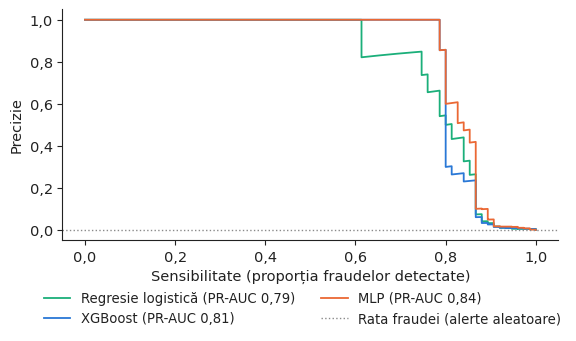

In [5]:
# paired bootstrap of the PR-AUC difference on the test rows (seed-averaged scores), 2,000 resamples, seed 20261108
PM = {k: np.mean(v, axis=0) for k, v in P.items()}
rng = np.random.default_rng(20261108)
te_idx = np.where(ite)[0]
def boot(a_, b_, B=2000):
    diffs = []
    for _ in range(B):
        i = rng.choice(te_idx, len(te_idx), replace=True)
        if y[i].sum() == 0:
            continue
        diffs.append(average_precision_score(y[i], PM[a_][i], sample_weight=w[i]) - average_precision_score(y[i], PM[b_][i], sample_weight=w[i]))
    diffs = np.array(diffs)
    return diffs.mean(), np.quantile(diffs, 0.025), np.quantile(diffs, 0.975), (diffs <= 0).mean()
BT = {}
for a_, b_ in [("XGBoost", "Logistic regression"), ("MLP", "Logistic regression"), ("XGBoost", "MLP")]:
    BT[(a_, b_)] = boot(a_, b_)
    print(f"PR-AUC {a_} - {b_}: {BT[(a_, b_)][0]:+.3f}  95% CI [{BT[(a_, b_)][1]:+.3f}, {BT[(a_, b_)][2]:+.3f}],  share <= 0: {BT[(a_, b_)][3]:.3f}")
NMOD = {"Logistic regression": ("Logistic regression", "Regresie logistică"), "XGBoost": ("XGBoost", "XGBoost"), "MLP": ("MLP", "MLP")}
COL = {"Logistic regression": cu.PAL["HU"], "XGBoost": cu.PAL["RO"], "MLP": cu.PAL["DE_LU"]}
def fig_pr(lang):
    fig, ax = plt.subplots(figsize=(6.4, 3.0))
    for k in P:
        pr, rc, _ = precision_recall_curve(y[ite], PM[k][ite], sample_weight=w[ite])
        ax.plot(rc, pr, color=COL[k], label=cu.T(lang, *NMOD[k]) + f" (PR-AUC {cu.fmt(res.loc[k, 'PRAUC'], 2, lang)})")
    ax.axhline(y[ite].sum() / w[ite].sum(), color=cu.MUTED, ls=":", lw=1, label=cu.T(lang, "Fraud rate (random alerts)", "Rata fraudei (alerte aleatoare)"))
    ax.set_xlabel(cu.T(lang, "Recall (share of frauds caught)", "Sensibilitate (proporția fraudelor detectate)"))
    ax.set_ylabel(cu.T(lang, "Precision", "Precizie"))
    cu.comma_axis(ax, lang, "x"); cu.comma_axis(ax, lang, "y")
    cu.legend_bottom(fig, ncol=2)
    return fig
cu.save_both(fig_pr, "f2_pr_curves")
tab = res[["AUC", "PRAUC", "PRAUC_sd", "Recall", "Precision"]].copy()
tab.index = [NMOD[k] for k in tab.index]
cu.write_table(tab, "models", [("Model", "Model"), ("ROC-AUC", "ROC-AUC"), ("PR-AUC", "PR-AUC"), ("sd PR-AUC", "abatere PR-AUC"),
                                ("Recall at 0.5\\,\\%", "Sensibilitate la 0,5\\,\\%"), ("Precision at 0.5\\,\\%", "Precizie la 0,5\\,\\%")],
               digits=3, best={"AUC": "max", "PRAUC": "max", "Recall": "max", "Precision": "max"})
cu.show_table(res, best={"AUC": "max", "PRAUC": "max"}, digits=3)

## 3. Explicații globale: variabilele folosite de arbori și de rețea

Spearman rank correlation of mean |SHAP|: XGBoost-MLP 0.530, XGBoost-logit 0.570; top-10 overlap XGBoost-MLP: 6 of 10
            XGBoost   MLP  Logistic regression
V4             17.1  11.2                 19.1
V14            16.1   8.3                  9.3
V10             8.8   4.9                  8.8
V12             7.9   6.8                  6.1
V8              5.1   3.8                  3.4
log_amount      4.7   2.0                  2.6
V19             3.2   2.6                  1.3
V24             3.2   3.5                  3.5
V22             3.0   2.3                  6.6
V17             2.9   1.6                  0.2


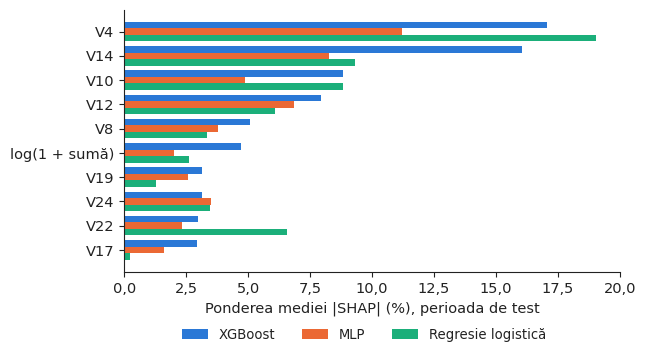

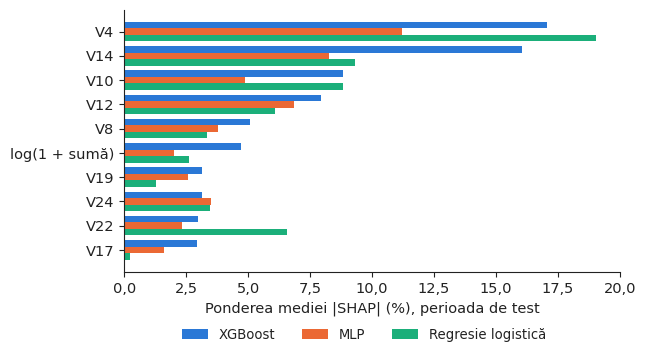

In [6]:
from scipy.stats import spearmanr
# XGBoost: exact TreeSHAP on all test rows (log-odds scale)
sv_x = shap.TreeExplainer(XGB0).shap_values(X[ite])
# MLP: expected gradients (GradientExplainer) with 300 training rows as background, on all test frauds + 1,000 test legitimate rows
rng2 = np.random.default_rng(0)
bg = torch.tensor(Xs[rng2.choice(np.where(itr)[0], 300, replace=False)], dtype=torch.float32)
ex_rows = np.r_[np.where(ite & (y == 1))[0], rng2.choice(np.where(ite & (y == 0))[0], 1000, replace=False)]
sv_m = shap.GradientExplainer(MLP0, bg).shap_values(torch.tensor(Xs[ex_rows], dtype=torch.float32), rseed=0)
sv_m = np.asarray(sv_m).reshape(len(ex_rows), -1)
# logistic regression: exact linear SHAP  phi_j = beta_j (x_j - mean_j)
sv_l = LR0.coef_[0] * (Xs[ex_rows] - Xs[itr].mean(0))
# comparable rows for all three models: the same test rows, legitimate rows re-weighted to the population
pos = {r: i for i, r in enumerate(np.where(ite)[0])}
sv_x_rows = sv_x[[pos[r] for r in ex_rows]]
wr = np.where(y[ex_rows] == 1, 1.0, (w[ite & (y == 0)].sum()) / 1000)
imp = pd.DataFrame({k: (np.abs(v) * wr[:, None]).sum(0) / wr.sum() for k, v in [("XGBoost", sv_x_rows), ("MLP", sv_m), ("Logistic regression", sv_l)]}, index=FEAT)
share = imp / imp.sum()
rk = share.rank(ascending=False)
rho_xm = spearmanr(share.XGBoost, share.MLP).statistic
rho_xl = spearmanr(share.XGBoost, share["Logistic regression"]).statistic
top10 = lambda c: set(share[c].sort_values(ascending=False).index[:10])
ov_xm = len(top10("XGBoost") & top10("MLP"))
order = share.XGBoost.sort_values(ascending=False).index
print("Spearman rank correlation of mean |SHAP|: XGBoost-MLP %.3f, XGBoost-logit %.3f; top-10 overlap XGBoost-MLP: %d of 10" % (rho_xm, rho_xl, ov_xm))
print((100 * share.loc[order[:10]]).round(1))
NM = {f: (f, f) for f in FEAT} | {"log_amount": ("log(1 + amount)", "log(1 + sumă)")}
def fig_shap(lang):
    fig, ax = plt.subplots(figsize=(6.4, 3.4))
    top = order[:10][::-1]; yy = np.arange(len(top)); hgt = 0.27
    for j, (k, c) in enumerate([("XGBoost", cu.PAL["RO"]), ("MLP", cu.PAL["DE_LU"]), ("Logistic regression", cu.PAL["HU"])]):
        ax.barh(yy + (1 - j) * hgt, 100 * share.loc[top, k], height=hgt, color=c, label=cu.T(lang, *NMOD[k]))
    ax.set_yticks(yy); ax.set_yticklabels([cu.T(lang, *NM[f]) for f in top])
    ax.set_xlabel(cu.T(lang, "Share of mean |SHAP| (%), test period", "Ponderea mediei |SHAP| (%), perioada de test"))
    cu.comma_axis(ax, lang, "x")
    cu.legend_bottom(fig, ncol=3)
    return fig
cu.save_both(fig_shap, "f3_shap_global", headline=True)

## 4. Explicația locală a unei tranzacții semnalate

row 25351 hour 42.9, amount 1504.93 EUR, XGBoost fraud probability 0.7694, MLP 0.6291, logit 0.9100


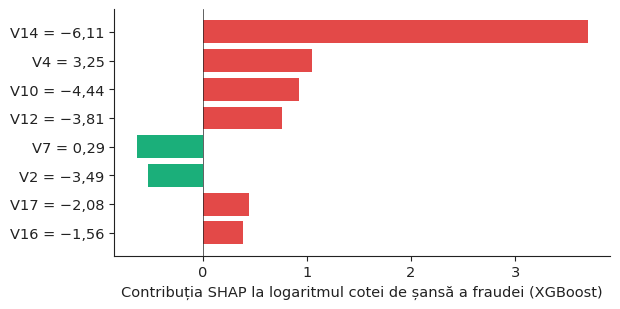

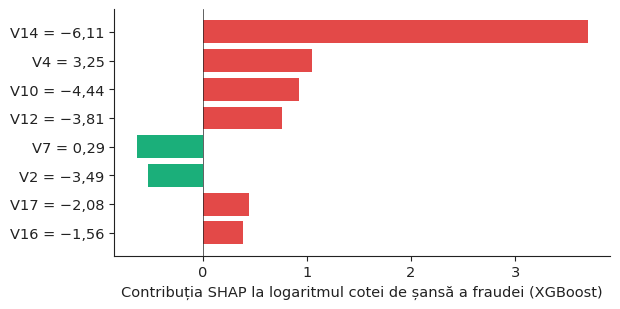

In [7]:
pt = PM["XGBoost"]
cand = np.where(ite & (y == 1))[0]
i_loc = cand[np.argmax(pt[cand] * d.Amount.values[cand])]     # the test fraud with the largest expected loss p x amount
sv_loc = pd.Series(sv_x[pos[i_loc]], index=FEAT)
top_loc = sv_loc.abs().sort_values(ascending=False).index[:8]
print("row", i_loc, "hour %.1f, amount %.2f EUR, XGBoost fraud probability %.4f, MLP %.4f, logit %.4f" %
      (d.Time[i_loc] / 3600, d.Amount[i_loc], pt[i_loc], PM["MLP"][i_loc], PM["Logistic regression"][i_loc]))
def fig_local(lang):
    fig, ax = plt.subplots(figsize=(6.4, 3.2))
    s_ = sv_loc[top_loc][::-1]
    xv = d.loc[i_loc, list(s_.index)]
    lab = [cu.T(lang, *NM[k]) + " = " + cu.fmt(float(xv[k]), 2, lang).replace("-", "−") for k in s_.index]
    ax.barh(lab, s_.values, color=[cu.PAL["c8"] if v > 0 else cu.PAL["HU"] for v in s_.values])
    ax.axvline(0, color=cu.INK, lw=0.5)
    ax.set_xlabel(cu.T(lang, "SHAP contribution to the log-odds of fraud (XGBoost)", "Contribuția SHAP la logaritmul cotei de șansă a fraudei (XGBoost)"))
    cu.comma_axis(ax, lang, "x")
    return fig
cu.save_both(fig_local, "f4_local")

## 5. Eliminarea variabilelor: contribuția variabilelor principale la performanță

       mean           std       
kind random    top random    top
k                               
0     0.812  0.812  0.005  0.005
1     0.817  0.811  0.001  0.006
2     0.808  0.808  0.004  0.009
3     0.809  0.766  0.011  0.003
5     0.795  0.747  0.038  0.014
8     0.794  0.733  0.032  0.005
10    0.786  0.738  0.029  0.007


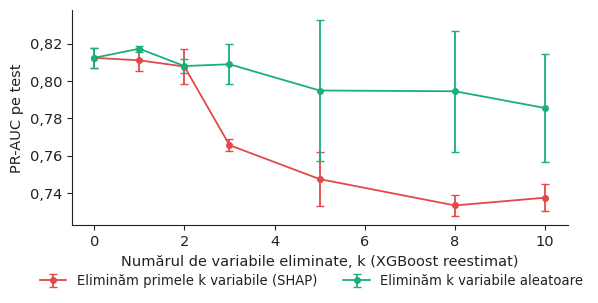

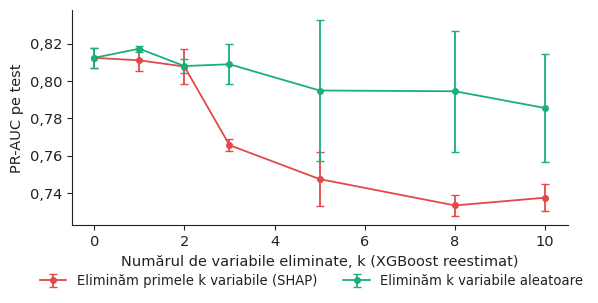

In [8]:
# analogue of the paper's edge-type ablation (Delta_r = AUC(G) - AUC(G without relation r)): remove the k most important variables
# (by XGBoost mean |SHAP|), refit XGBoost on the remaining ones, and compare with removing k random variables. Three seeds each.
def fit_xgb(cols, seed):
    m = xgb.XGBClassifier(n_estimators=1000, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8,
                          eval_metric="logloss", early_stopping_rounds=100, random_state=seed, n_jobs=4, tree_method="hist")
    m.fit(X[itr][:, cols], y[itr], eval_set=[(X[iva][:, cols], y[iva])], verbose=False)
    return correct(m.predict_proba(X[:, cols])[:, 1])
KS = [0, 1, 2, 3, 5, 8, 10]
idx_of = {f: j for j, f in enumerate(FEAT)}
rank_x = [idx_of[f] for f in share.XGBoost.sort_values(ascending=False).index]
abl = []
rng3 = np.random.default_rng(7)
for k in KS:
    for s in SEEDS[:3]:
        keep = [j for j in range(len(FEAT)) if j not in rank_x[:k]]
        abl.append(dict(k=k, kind="top", seed=s, PRAUC=metrics(fit_xgb(keep, s))["PRAUC"]))
        drop = rng3.choice(len(FEAT), k, replace=False)
        keep_r = [j for j in range(len(FEAT)) if j not in drop]
        abl.append(dict(k=k, kind="random", seed=s, PRAUC=metrics(fit_xgb(keep_r, s))["PRAUC"]))
abl = pd.DataFrame(abl)
ab = abl.groupby(["kind", "k"]).PRAUC.agg(["mean", "std"]).unstack(0)
print(ab.round(3))
base = ab[("mean", "top")][0]
d5_top, d5_rand = base - ab[("mean", "top")][5], base - ab[("mean", "random")][5]
d10_top = base - ab[("mean", "top")][10]
def fig_abl(lang):
    fig, ax = plt.subplots(figsize=(6.4, 2.8))
    for kind, c, en, ro in [("top", cu.PAL["c8"], "Remove the k most important variables (SHAP)", "Eliminăm primele k variabile (SHAP)"),
                            ("random", cu.PAL["HU"], "Remove k random variables", "Eliminăm k variabile aleatoare")]:
        m_, s_ = ab[("mean", kind)], ab[("std", kind)]
        ax.errorbar(m_.index, m_.values, yerr=s_.values, color=c, marker="o", ms=4, capsize=3, label=cu.T(lang, en, ro))
    ax.set_xlabel(cu.T(lang, "Number of variables removed, k (XGBoost refitted)", "Numărul de variabile eliminate, k (XGBoost reestimat)"))
    ax.set_ylabel(cu.T(lang, "Test PR-AUC", "PR-AUC pe test"))
    cu.comma_axis(ax, lang, "y")
    cu.legend_bottom(fig, ncol=2)
    return fig
cu.save_both(fig_abl, "f5_ablation")

## 6. Pragul de alertă: costul unei verificări și suma expusă riscului

                                                    alerts  caught  caught_eur  cost
(No model: no alerts, Fără model: nicio alertă)        0.0       0         0.0   7.7
(Logistic regression, threshold 0.5, Regresie l...    58.0      48      3671.6   4.3
(Logistic regression, cost rule p x amount > c,...    93.0      23      5276.7   2.9
(XGBoost, threshold 0.5, XGBoost, prag 0,5)           51.0      51      3755.8   4.2
(XGBoost, cost rule p x amount > c, XGBoost, re...    84.0      24      5286.0   2.9
(MLP, threshold 0.5, MLP, prag 0,5)                   49.0      49      4906.5   3.1
(MLP, cost rule p x amount > c, MLP, regula de ...    83.0      23      5276.7   2.9


,alerts,caught,caught_eur,cost
"('No model: no alerts', 'Fără model: nicio alertă')",0.0,0,0.0,7.7
"('Logistic regression, threshold 0.5', 'Regresie logistică, prag 0,5')",58.0,48,3671.6,4.3
"('Logistic regression, cost rule p x amount > c', 'Regresie logistică, regula de cost p x sumă > c')",93.0,23,5276.7,2.9
"('XGBoost, threshold 0.5', 'XGBoost, prag 0,5')",51.0,51,3755.8,4.2
"('XGBoost, cost rule p x amount > c', 'XGBoost, regula de cost p x sumă > c')",84.0,24,5286.0,2.9
"('MLP, threshold 0.5', 'MLP, prag 0,5')",49.0,49,4906.5,3.1
"('MLP, cost rule p x amount > c', 'MLP, regula de cost p x sumă > c')",83.0,23,5276.7,2.9


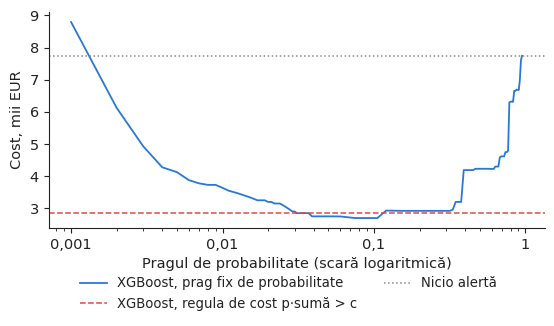

In [9]:
C_REV = 5.0      # cost of reviewing one alert, EUR (assumption chosen a priori; change it)
amt = d.Amount.values
def cost(flag, m=ite):
    """Population cost on the test period: reviews of all alerts + amounts of missed frauds (weights scale the 10 % sample)."""
    f, yy, ww = flag[m], y[m], w[m]
    return (C_REV * (ww * f).sum() + (amt[m] * yy * (1 - f)).sum())
pol = {}
pol[("No model: no alerts", "Fără model: nicio alertă")] = np.zeros(n, bool)
for k in P:
    pol[(NMOD[k][0] + ", threshold 0.5", NMOD[k][1] + ", prag 0,5")] = PM[k] >= 0.5
    pol[(NMOD[k][0] + ", cost rule p x amount > c", NMOD[k][1] + ", regula de cost p x sumă > c")] = PM[k] * amt > C_REV
rows = []
for lab, f in pol.items():
    m = ite
    rows.append(dict(lab=lab, alerts=(w[m] * f[m]).sum(), caught=(y[m] * f[m]).sum(), caught_eur=(amt[m] * y[m] * f[m]).sum(), cost=cost(f) / 1000))
cost_tab = pd.DataFrame(rows).set_index("lab")
cost_tab.index = list(pol.keys())
print(cost_tab.round(1))
c_none = cost_tab.iloc[0].cost
key_x_rule = ("XGBoost, cost rule p x amount > c", "XGBoost, regula de cost p x sumă > c")
key_x_05 = ("XGBoost, threshold 0.5", "XGBoost, prag 0,5")
fraud_eur = (amt[ite] * y[ite]).sum()
ct = cost_tab.copy(); ct.index = [(a_.replace("p x amount > c", "$p\\cdot A>c$"), b_.replace("p x sumă > c", "$p\\cdot A>c$")) for a_, b_ in ct.index]
cu.write_table(ct, "cost", [("Alert policy (test period)", "Politica de alertă (perioada de test)"), ("Alerts", "Alerte"), ("Frauds caught", "Fraude detectate"),
                            ("EUR caught", "EUR recuperați"), ("Cost, thousand EUR", "Cost, mii EUR")],
               digits={"alerts": 0, "caught": 0, "caught_eur": 0, "cost": 2}, best={"cost": "min"})
# total cost as a function of a fixed probability threshold (XGBoost), with the cost rule as a reference line
grid = np.r_[np.linspace(0.001, 0.05, 50), np.linspace(0.06, 0.95, 60)]
cg = np.array([cost(PM["XGBoost"] >= t) / 1000 for t in grid])
def fig_cost(lang):
    fig, ax = plt.subplots(figsize=(6.4, 2.8))
    ax.plot(grid, cg, color=cu.PAL["RO"], label=cu.T(lang, "XGBoost, fixed probability threshold", "XGBoost, prag fix de probabilitate"))
    ax.axhline(cost_tab.loc[[key_x_rule]].cost.iloc[0], color=cu.PAL["c8"], ls="--", lw=1.1,
               label=cu.T(lang, "XGBoost, cost rule p·amount > c", "XGBoost, regula de cost p·sumă > c"))
    ax.axhline(c_none, color=cu.MUTED, ls=":", lw=1.1, label=cu.T(lang, "No alerts", "Nicio alertă"))
    ax.set_xscale("log")
    ax.set_xlabel(cu.T(lang, "Probability threshold (log scale)", "Pragul de probabilitate (scară logaritmică)"))
    ax.set_ylabel(cu.T(lang, "Cost, thousand EUR", "Cost, mii EUR"))
    cu.comma_axis(ax, lang, "y")
    if lang == "ro":
        from matplotlib.ticker import FuncFormatter
        ax.xaxis.set_major_formatter(FuncFormatter(lambda v, p_: ("%g" % v).replace(".", ",")))
    cu.legend_bottom(fig, ncol=2)
    return fig
cu.save_both(fig_cost, "f6_cost")
cu.show_table(cost_tab, best={"cost": "min"}, digits=1)

In [10]:
r_ = res
NMf = lambda f: NM[f]
cu.write_numbers({
    "nRows": int(n), "nFraud": int(y.sum()), "nTest": int(ite.sum()), "nTestFraud": int(y[ite].sum()), "nValFraud": int(y[iva].sum()), "nTrainFraud": int(y[itr].sum()),
    "popTest": int(round(w[ite].sum())), "rateTest": 100 * y[ite].sum() / w[ite].sum(), "hoursTest": float(HOURS), "beta": float(BETA),
    "lAUC": r_.loc["Logistic regression", "AUC"], "xAUC": r_.loc["XGBoost", "AUC"], "mAUC": r_.loc["MLP", "AUC"],
    "lPR": r_.loc["Logistic regression", "PRAUC"], "xPR": r_.loc["XGBoost", "PRAUC"], "mPR": r_.loc["MLP", "PRAUC"],
    "xPRsd": r_.loc["XGBoost", "PRAUC_sd"], "mPRsd": r_.loc["MLP", "PRAUC_sd"],
    "lRec": r_.loc["Logistic regression", "Recall"], "xRec": r_.loc["XGBoost", "Recall"], "mRec": r_.loc["MLP", "Recall"],
    "xPrec": r_.loc["XGBoost", "Precision"], "mPrec": r_.loc["MLP", "Precision"], "lPrec": r_.loc["Logistic regression", "Precision"],
    "dXL": BT[("XGBoost", "Logistic regression")][0], "dXLlo": BT[("XGBoost", "Logistic regression")][1], "dXLhi": BT[("XGBoost", "Logistic regression")][2],
    "dXM": BT[("XGBoost", "MLP")][0], "dXMlo": BT[("XGBoost", "MLP")][1], "dXMhi": BT[("XGBoost", "MLP")][2],
    "dML": BT[("MLP", "Logistic regression")][0], "dMLlo": BT[("MLP", "Logistic regression")][1], "dMLhi": BT[("MLP", "Logistic regression")][2],
    "top": NMf(order[0]), "second": NMf(order[1]), "third": NMf(order[2]),
    "topShare": 100 * share.XGBoost[order[0]], "topThreeShare": 100 * share.XGBoost[order[:3]].sum(),
    "rhoXM": float(rho_xm), "rhoXL": float(rho_xl), "overlapXM": int(ov_xm),
    "mlpTop": NMf(share.MLP.sort_values(ascending=False).index[0]),
    "locHour": float(d.Time[i_loc] / 3600), "locAmount": float(d.Amount[i_loc]), "locProb": float(pt[i_loc]),
    "locTop": NMf(top_loc[0]), "locSecond": NMf(top_loc[1]),
    "ablBase": float(base), "ablTopFive": float(ab[("mean", "top")][5]), "ablRandFive": float(ab[("mean", "random")][5]),
    "ablTopTen": float(ab[("mean", "top")][10]), "dTopFive": float(d5_top), "dRandFive": float(d5_rand),
    "cRev": C_REV, "costNone": float(c_none), "costRule": float(cost_tab.loc[[key_x_rule]].cost.iloc[0]),
    "costHalf": float(cost_tab.loc[[key_x_05]].cost.iloc[0]), "saveRule": float(c_none - cost_tab.loc[[key_x_rule]].cost.iloc[0]),
    "alertsRule": float(cost_tab.loc[[key_x_rule]].alerts.iloc[0]), "caughtRule": int(cost_tab.loc[[key_x_rule]].caught.iloc[0]),
    "caughtHalf": int(cost_tab.loc[[key_x_05]].caught.iloc[0]), "fraudEur": float(fraud_eur / 1000),
    "caughtEurRule": float(cost_tab.loc[[key_x_rule]].caught_eur.iloc[0] / 1000), "bestFixedCost": float(cg.min()), "bestFixedThr": float(grid[np.argmin(cg)]),
}, digits={"rateTest": 3, "hoursTest": 1, "beta": 4, "lAUC": 3, "xAUC": 3, "mAUC": 3, "lPR": 3, "xPR": 3, "mPR": 3, "xPRsd": 3, "mPRsd": 3,
           "lRec": 2, "xRec": 2, "mRec": 2, "xPrec": 2, "mPrec": 2, "lPrec": 2, "dXL": 3, "dXLlo": 3, "dXLhi": 3, "dXM": 3, "dXMlo": 3, "dXMhi": 3,
           "dML": 3, "dMLlo": 3, "dMLhi": 3, "topShare": 1, "topThreeShare": 1, "rhoXM": 2, "rhoXL": 2, "locHour": 1, "locAmount": 2, "locProb": 3,
           "ablBase": 3, "ablTopFive": 3, "ablRandFive": 3, "ablTopTen": 3, "dTopFive": 3, "dRandFive": 3, "cRev": 0,
           "costNone": 1, "costRule": 1, "costHalf": 1, "saveRule": 1, "alertsRule": 0, "fraudEur": 1, "caughtEurRule": 1, "bestFixedCost": 1, "bestFixedThr": 3})
print(open("numbers_en.tex", encoding="utf-8").read())

% generated by the case notebook -- do not edit
\newcommand{\NnRows}{28,924}
\newcommand{\NnFraud}{492}
\newcommand{\NnTest}{5,785}
\newcommand{\NnTestFraud}{75}
\newcommand{\NnValFraud}{57}
\newcommand{\NnTrainFraud}{360}
\newcommand{\NpopTest}{57,174}
\newcommand{\NrateTest}{0.131}
\newcommand{\NhoursTest}{7.7}
\newcommand{\Nbeta}{0.1000}
\newcommand{\NlAUC}{0.982}
\newcommand{\NxAUC}{0.983}
\newcommand{\NmAUC}{0.980}
\newcommand{\NlPR}{0.789}
\newcommand{\NxPR}{0.815}
\newcommand{\NmPR}{0.837}
\newcommand{\NxPRsd}{0.005}
\newcommand{\NmPRsd}{0.004}
\newcommand{\NlRec}{0.87}
\newcommand{\NxRec}{0.86}
\newcommand{\NmRec}{0.87}
\newcommand{\NxPrec}{0.22}
\newcommand{\NmPrec}{0.22}
\newcommand{\NlPrec}{0.22}
\newcommand{\NdXL}{0.023}
\newcommand{\NdXLlo}{$-$0.022}
\newcommand{\NdXLhi}{0.078}
\newcommand{\NdXM}{$-$0.020}
\newcommand{\NdXMlo}{$-$0.048}
\newcommand{\NdXMhi}{0.003}
\newcommand{\NdML}{0.046}
\newcommand{\NdMLlo}{0.004}
\newcommand{\NdMLhi}{0.107}
\newcommand{\Ntop}{V4}
\newc

In [11]:
# slide-ready summary for the lecture box "Research from our group" (max 6 lines), both languages; every number comes from this notebook
for lang in ("en", "ro"):
    F = lambda v, nd=2: cu.fmt(float(v), nd, lang)
    t = lambda en, ro: ro if lang == "ro" else en
    j = 1 if lang == "ro" else 0
    lines = [
        t("\\textbf{Explainable fraud detection} (Diaconu \\& Pele, 2026, PICBE): on IEEE-CIS, XGBoost reaches ROC-AUC 0.9763, CatBoost 0.9636, GraphSAGE 0.8729 (Table~2); SHAP rankings agree across the tabular models; graph ablation adds the relational view.",
          "\\textbf{Detectarea explicabilă a fraudei} (Diaconu și Pele, 2026, PICBE): pe datele IEEE-CIS, XGBoost atinge ROC-AUC 0,9763, CatBoost 0,9636, GraphSAGE 0,8729 (Tabelul~2); ordonările SHAP coincid între modelele tabelare; eliminarea relațiilor din graf adaugă perspectiva relațională."),
        t(f"Our replication (ULB card data, time-ordered split, 5 seeds): test PR-AUC XGBoost {F(r_.loc['XGBoost', 'PRAUC'], 3)}, MLP {F(r_.loc['MLP', 'PRAUC'], 3)}, logistic {F(r_.loc['Logistic regression', 'PRAUC'], 3)}.",
          f"Replicarea noastră (datele ULB, împărțire cronologică, 5 rulări): PR-AUC pe test XGBoost {F(r_.loc['XGBoost', 'PRAUC'], 3)}, MLP {F(r_.loc['MLP', 'PRAUC'], 3)}, regresie logistică {F(r_.loc['Logistic regression', 'PRAUC'], 3)}."),
        t(f"SHAP: trees and network share {ov_xm} of their top 10 variables (rank correlation {F(rho_xm)}); removing the top 5 variables costs {F(d5_top, 3)} PR-AUC.",
          f"SHAP: arborii și rețeaua au în comun {ov_xm} dintre primele 10 variabile (corelația rangurilor {F(rho_xm)}); eliminarea primelor 5 variabile reduce PR-AUC cu {F(d5_top, 3)}."),
        t(f"Decision: alert when fraud probability $\\times$ amount $>$ review cost; on the test period this cuts cost from {F(c_none, 1)} to {F(cost_tab.loc[[key_x_rule]].cost.iloc[0], 1)} thousand EUR.",
          f"Decizia: alertă cînd probabilitatea de fraudă $\\times$ suma $>$ costul verificării; în perioada de test costul scade de la {F(c_none, 1)} la {F(cost_tab.loc[[key_x_rule]].cost.iloc[0], 1)} mii EUR."),
    ]
    with open(f"slide_summary_{lang}.tex", "w", encoding="utf-8") as fh:
        fh.write("% slide-ready summary for the lecture box 'Research from our group' (max 6 lines); generated by the notebook\n\\begin{itemize}\\setlength{\\itemsep}{2pt}\n")
        for l_ in lines:
            fh.write("  \\item " + l_ + "\n")
        fh.write("\\end{itemize}\n")
print(open("slide_summary_en.tex", encoding="utf-8").read())

% slide-ready summary for the lecture box 'Research from our group' (max 6 lines); generated by the notebook
\begin{itemize}\setlength{\itemsep}{2pt}
  \item \textbf{Explainable fraud detection} (Diaconu \& Pele, 2026, PICBE): on IEEE-CIS, XGBoost reaches ROC-AUC 0.9763, CatBoost 0.9636, GraphSAGE 0.8729 (Table~2); SHAP rankings agree across the tabular models; graph ablation adds the relational view.
  \item Our replication (ULB card data, time-ordered split, 5 seeds): test PR-AUC XGBoost 0.815, MLP 0.837, logistic 0.789.
  \item SHAP: trees and network share 6 of their top 10 variables (rank correlation 0.53); removing the top 5 variables costs 0.065 PR-AUC.
  \item Decision: alert when fraud probability $\times$ amount $>$ review cost; on the test period this cuts cost from 7.7 to 2.9 thousand EUR.
\end{itemize}



## Exerciții suplimentare
1. Înlocuiți împărțirea cronologică cu împărțirea aleatoare 70/30 din lucrare. Cît se modifică ROC-AUC și PR-AUC și de ce rezultatul obținut cu împărțirea cronologică este cel care trebuie raportat comitetului de risc?
2. Modificați costul unei verificări de la 5 la 25 EUR. Cîte alerte dispar și ce fraude nu mai sînt verificate?
3. Eliminați variabila `log_amount`. Se modifică ordinea variabilelor V? Ce spune acest lucru despre explicarea variabilelor corelate?